In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Project directory: c:\Users\Medhavie Gupta\OneDrive\Desktop\Projects\Cognify\Cognifyz_Task4_Location_Analysis
Data directory: c:\Users\Medhavie Gupta\OneDrive\Desktop\Projects\Cognify\Cognifyz_Task4_Location_Analysis\data
Output directory: c:\Users\Medhavie Gupta\OneDrive\Desktop\Projects\Cognify\Cognifyz_Task4_Location_Analysis\outputs


In [3]:
csv_files = list(DATA_DIR.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

CSV files found: 1
Dataset .csv


In [4]:
DATASET_PATH = DATA_DIR / "Dataset.csv"

df = pd.read_csv(DATASET_PATH, encoding="utf-8-sig")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Medhavie Gupta\\OneDrive\\Desktop\\Projects\\Cognify\\Cognifyz_Task4_Location_Analysis\\data\\Dataset.csv'

In [5]:
# Locate the project directory and dataset automatically

current_dir = Path.cwd()

print("Current working directory:", current_dir)

search_roots = [current_dir, *current_dir.parents]

dataset_matches = []

for root in search_roots:
    data_folder = root / "data"

    if data_folder.exists():
        dataset_matches.extend(data_folder.glob("*.csv"))

    if dataset_matches:
        break

print("\nCSV files found:")

for file in dataset_matches:
    print(file.name)

Current working directory: c:\Users\Medhavie Gupta\OneDrive\Desktop\Projects\Cognify\Cognifyz_Task4_Location_Analysis\Task4_Location_Analysis.ipynb

CSV files found:
Dataset .csv


In [6]:
# Load the actual restaurant dataset

if not dataset_matches:
    raise FileNotFoundError(
        "No CSV file found in the project's data folder. "
        "Check the folder location."
    )

DATASET_PATH = dataset_matches[0]

df = pd.read_csv(
    DATASET_PATH,
    encoding="utf-8-sig"
)

print("Dataset loaded successfully!")
print("Dataset path:", DATASET_PATH)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Dataset path: c:\Users\Medhavie Gupta\OneDrive\Desktop\Projects\Cognify\Cognifyz_Task4_Location_Analysis\data\Dataset .csv
Number of rows: 9551
Number of columns: 21


In [7]:
df.head(10)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
5,18189371,Din Tai Fung,162,Mandaluyong City,"Ground Floor, Mega Fashion Hall, SM Megamall, ...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056314,14.583764,Chinese,...,Botswana Pula(P),No,No,No,No,3,4.4,Green,Very Good,336
6,6300781,Buffet 101,162,Pasay City,"Building K, SM By The Bay, Sunset Boulevard, M...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979667,14.531333,"Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.0,Green,Very Good,520
7,6301290,Vikings,162,Pasay City,"Building B, By The Bay, Seaside Boulevard, Mal...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979333,14.540000,"Seafood, Filipino, Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.2,Green,Very Good,677
8,6300010,Spiral - Sofitel Philippine Plaza Manila,162,Pasay City,"Plaza Level, Sofitel Philippine Plaza Manila, ...","Sofitel Philippine Plaza Manila, Pasay City","Sofitel Philippine Plaza Manila, Pasay City, P...",120.980090,14.552990,"European, Asian, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.9,Dark Green,Excellent,621
9,6314987,Locavore,162,Pasig City,"Brixton Technology Center, 10 Brixton Street, ...",Kapitolyo,"Kapitolyo, Pasig City",121.056532,14.572041,Filipino,...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,532


In [8]:
print("Dataset columns:\n")

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

Dataset columns:

1. Restaurant ID
2. Restaurant Name
3. Country Code
4. City
5. Address
6. Locality
7. Locality Verbose
8. Longitude
9. Latitude
10. Cuisines
11. Average Cost for two
12. Currency
13. Has Table booking
14. Has Online delivery
15. Is delivering now
16. Switch to order menu
17. Price range
18. Aggregate rating
19. Rating color
20. Rating text
21. Votes


In [9]:
print("Dataset information:\n")

df.info()

print("\nFirst five records:")
display(df.head())

Dataset information:

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to 

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [10]:
# Normalize column names for matching

def normalize_column(column):
    return (
        str(column)
        .strip()
        .lower()
        .replace("_", " ")
        .replace("-", " ")
    )


normalized_columns = {
    normalize_column(column): column
    for column in df.columns
}

column_aliases = {
    "name": [
        "restaurant name", "name", "restaurant"
    ],
    "city": [
        "city", "city name"
    ],
    "locality": [
        "locality", "area", "neighborhood", "neighbourhood"
    ],
    "latitude": [
        "latitude", "lat"
    ],
    "longitude": [
        "longitude", "long", "lon", "lng"
    ],
    "rating": [
        "aggregate rating", "rating", "rate"
    ],
    "cuisines": [
        "cuisines", "cuisine"
    ],
    "cost": [
        "average cost for two", "average cost",
        "cost for two", "cost"
    ],
    "price_range": [
        "price range", "price category"
    ],
    "votes": [
        "votes", "vote count"
    ]
}

column_map = {}

for field, aliases in column_aliases.items():
    for alias in aliases:
        normalized_alias = normalize_column(alias)

        if normalized_alias in normalized_columns:
            column_map[field] = normalized_columns[normalized_alias]
            break

print("Detected columns:\n")

for field, column in column_map.items():
    print(f"{field}: {column}")

Detected columns:

name: Restaurant Name
city: City
locality: Locality
latitude: Latitude
longitude: Longitude
rating: Aggregate rating
cuisines: Cuisines
cost: Average Cost for two
price_range: Price range
votes: Votes


In [11]:
# Work on a separate copy of the original dataset

restaurant_df = df.copy()

# Convert coordinates to numeric values

for field in ["latitude", "longitude", "rating", "cost", "votes", "price_range"]:

    column = column_map.get(field)

    if column:
        restaurant_df[column] = pd.to_numeric(
            restaurant_df[column]
            .astype(str)
            .str.replace(",", "", regex=False)
            .str.strip()
            .str.replace("/5", "", regex=False),
            errors="coerce"
        )

# Ratings outside the valid 0–5 range are treated as invalid

rating_column = column_map.get("rating")

if rating_column:
    restaurant_df.loc[
        ~restaurant_df[rating_column].between(0, 5),
        rating_column
    ] = np.nan

print("Numerical conversion completed.")
display(restaurant_df.head())

Numerical conversion completed.


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [12]:
missing_summary = pd.DataFrame({
    "Missing Values": restaurant_df.isna().sum(),
    "Missing Percentage": (
        restaurant_df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
Cuisines,9,0.09
Restaurant Name,0,0.00
Country Code,0,0.00
City,0,0.00
Restaurant ID,0,0.00
Address,0,0.00
Locality,0,0.00
Longitude,0,0.00
Locality Verbose,0,0.00
Latitude,0,0.00


In [13]:
print("Total restaurant records:", len(restaurant_df))

exact_duplicates = restaurant_df.duplicated().sum()

print("Exact duplicate records:", exact_duplicates)

duplicate_rows = restaurant_df[
    restaurant_df.duplicated(keep=False)
]

display(duplicate_rows.head(10))

Total restaurant records: 9551
Exact duplicate records: 0


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes


In [14]:
latitude_column = column_map.get("latitude")
longitude_column = column_map.get("longitude")

if not latitude_column or not longitude_column:
    raise ValueError(
        "Latitude or longitude was not detected. "
        "Check the column names printed in Step 5."
    )

valid_coordinates = (
    restaurant_df[latitude_column].between(-90, 90)
    & restaurant_df[longitude_column].between(-180, 180)
)

mapped_df = restaurant_df.loc[valid_coordinates].copy()

print("Total records:", len(restaurant_df))
print("Records with valid coordinates:", len(mapped_df))
print(
    "Records with invalid or missing coordinates:",
    len(restaurant_df) - len(mapped_df)
)

display(
    mapped_df[
        [latitude_column, longitude_column]
    ].head()
)

Total records: 9551
Records with valid coordinates: 9551
Records with invalid or missing coordinates: 0


,Latitude,Longitude
0,14.565443,121.027535
1,14.553708,121.014101
2,14.581404,121.056831
3,14.585318,121.056475
4,14.584450,121.057508


In [15]:
# Keep a clean dataset for geographical analysis

analysis_df = restaurant_df.copy()

# Normalize text columns

for field in ["name", "city", "locality", "cuisines"]:
    column = column_map.get(field)

    if column:
        analysis_df[column] = (
            analysis_df[column]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
        )

# Keep only records with valid coordinates for map analysis

map_df = analysis_df.loc[
    analysis_df[latitude_column].between(-90, 90)
    & analysis_df[longitude_column].between(-180, 180)
].copy()

print("Analysis dataset prepared.")
print("Total analysis records:", len(analysis_df))
print("Records available for mapping:", len(map_df))

Analysis dataset prepared.
Total analysis records: 9551
Records available for mapping: 9551


In [16]:
city_column = column_map.get("city")
locality_column = column_map.get("locality")
rating_column = column_map.get("rating")

total_restaurants = len(analysis_df)

total_cities = (
    analysis_df[city_column].nunique()
    if city_column else None
)

total_localities = (
    analysis_df[locality_column].nunique()
    if locality_column else None
)

average_rating = (
    analysis_df[rating_column].mean()
    if rating_column else np.nan
)

print("========== RESTAURANT ANALYTICS ==========")
print("Total restaurants:", total_restaurants)
print("Total cities:", total_cities)
print("Total localities:", total_localities)
print("Average rating:", average_rating)
print("Restaurants with valid coordinates:", len(map_df))

========== RESTAURANT ANALYTICS ==========
Total restaurants: 9551
Total cities: 141
Total localities: 1208
Average rating: 2.6663700136111403
Restaurants with valid coordinates: 9551


In [17]:
if not city_column:
    print("City column unavailable. Check the column mapping.")

else:
    city_counts = (
        analysis_df[city_column]
        .dropna()
        .value_counts()
        .rename_axis("City")
        .reset_index(name="Restaurant Count")
    )

    display(city_counts.head(20))

,City,Restaurant Count
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Ahmedabad,21
6,Amritsar,21
7,Bhubaneshwar,21
8,Guwahati,21
9,Lucknow,21


In [18]:
if not locality_column:
    print("Locality column unavailable. Check the column mapping.")

else:
    aggregation = {
        "Restaurant Count": (
            locality_column,
            "size"
        )
    }

    if rating_column:
        aggregation["Average Rating"] = (
            rating_column,
            "mean"
        )

    cost_column = column_map.get("cost")

    if cost_column:
        aggregation["Average Cost"] = (
            cost_column,
            "mean"
        )

    locality_summary = (
        analysis_df
        .dropna(subset=[locality_column])
        .groupby(locality_column)
        .agg(**aggregation)
        .reset_index()
        .sort_values(
            "Restaurant Count",
            ascending=False
        )
    )

    display(locality_summary.head(20))

,Locality,Restaurant Count,Average Rating,Average Cost
215,Connaught Place,122,3.686885,1175.000000
835,Rajouri Garden,99,3.591919,855.050505
971,Shahdara,87,1.413793,290.804598
273,Defence Colony,86,3.210465,741.279070
794,Pitampura,85,2.870588,449.411765
639,Malviya Nagar,85,3.428235,635.294118
655,Mayur Vihar Phase 1,84,2.026190,372.619048
834,Rajinder Nagar,81,2.943210,439.753086
870,Safdarjung,80,2.801250,580.000000
889,Satyaniketan,79,3.482278,537.974684


In [19]:
cuisine_column = column_map.get("cuisines")

if not cuisine_column:
    print("Cuisine column unavailable.")

else:
    cuisine_counts = (
        analysis_df[cuisine_column]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    cuisine_counts = cuisine_counts[
        cuisine_counts.ne("")
    ]

    cuisine_summary = (
        cuisine_counts
        .value_counts()
        .rename_axis("Cuisine")
        .reset_index(name="Restaurant Count")
    )

    display(cuisine_summary.head(20))

,Cuisine,Restaurant Count
0,North Indian,3960
1,Chinese,2735
2,Fast Food,1986
3,Mughlai,995
4,Italian,764
5,Bakery,745
6,Continental,736
7,Cafe,703
8,Desserts,653
9,South Indian,636


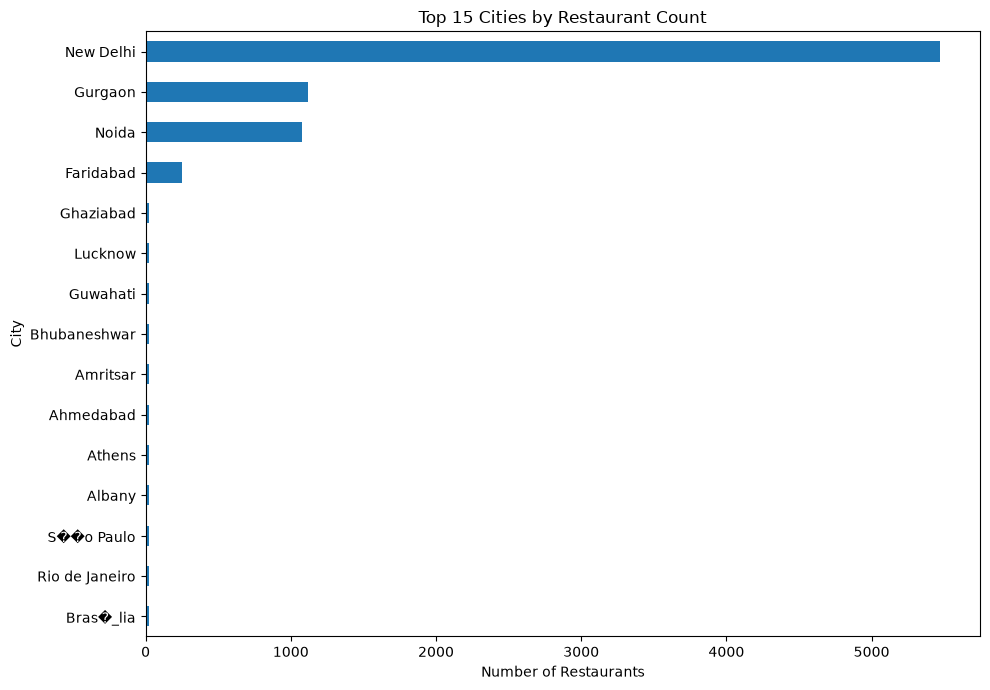

,mean,count
City,,
Pasig City,4.633333,3
Mandaluyong City,4.625000,4
London,4.535000,20
Taguig City,4.525000,4
Orlando,4.475000,20
Rest of Hawaii,4.410000,20
Tampa Bay,4.410000,20
Bangalore,4.375000,20
Dubai,4.370000,20


In [20]:
if city_column:

    city_chart = (
        analysis_df[city_column]
        .dropna()
        .value_counts()
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 7))

    city_chart.plot(kind="barh")

    plt.title("Top 15 Cities by Restaurant Count")
    plt.xlabel("Number of Restaurants")
    plt.ylabel("City")

    plt.tight_layout()
    plt.show()

    if rating_column:

        city_ratings = (
            analysis_df
            .dropna(subset=[city_column, rating_column])
            .groupby(city_column)[rating_column]
            .agg(["mean", "count"])
        )

        # Require at least three rated restaurants per city

        city_ratings = city_ratings[
            city_ratings["count"] >= 3
        ]

        city_ratings = city_ratings.sort_values(
            "mean",
            ascending=False
        ).head(15)

        display(city_ratings)

In [21]:
if map_df.empty:

    print("No valid coordinates are available for mapping.")

else:

    city_column = column_map.get("city")
    name_column = column_map.get("name")
    locality_column = column_map.get("locality")
    rating_column = column_map.get("rating")

    hover_columns = [
        column
        for column in [
            name_column,
            city_column,
            locality_column,
            rating_column
        ]
        if column and column in map_df.columns
    ]

    map_arguments = {
        "data_frame": map_df,
        "lat": latitude_column,
        "lon": longitude_column,
        "hover_data": hover_columns,
        "zoom": 3,
        "height": 650,
        "map_style": "open-street-map",
        "title": "Geographical Distribution of Restaurants"
    }

    if name_column:
        map_arguments["hover_name"] = name_column

    if rating_column:
        map_arguments["color"] = rating_column
        map_arguments["color_continuous_scale"] = "RdYlGn"

    fig = px.scatter_map(**map_arguments)

    fig.update_traces(
        marker={"size": 8, "opacity": 0.7}
    )

    fig.update_layout(
        margin={"l": 0, "r": 0, "t": 50, "b": 0}
    )

    fig.show()

In [22]:
print("========== LOCATION-BASED INSIGHTS ==========\n")

if city_column:

    city_counts = analysis_df[city_column].value_counts(
        dropna=True
    )

    if not city_counts.empty:
        print(
            f"City with the most restaurants in the dataset: "
            f"{city_counts.index[0]} "
            f"({city_counts.iloc[0]} restaurants)"
        )

if locality_column:

    locality_counts = analysis_df[
        locality_column
    ].value_counts(dropna=True)

    if not locality_counts.empty:
        print(
            f"Locality with the most restaurants: "
            f"{locality_counts.index[0]} "
            f"({locality_counts.iloc[0]} restaurants)"
        )

if rating_column:

    valid_ratings = analysis_df[rating_column].dropna()

    if not valid_ratings.empty:
        print(
            f"Overall average restaurant rating: "
            f"{valid_ratings.mean():.2f}/5"
        )

if cuisine_column and not cuisine_summary.empty:

    print(
        f"Most common cuisine: "
        f"{cuisine_summary.iloc[0]['Cuisine']}"
    )

========== LOCATION-BASED INSIGHTS ==========

City with the most restaurants in the dataset: New Delhi (5473 restaurants)
Locality with the most restaurants: Connaught Place (122 restaurants)
Overall average restaurant rating: 2.67/5
Most common cuisine: North Indian


In [23]:
# Create the output folder

OUTPUT_DIR = DATASET_PATH.parent.parent / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Export the cleaned dataset

analysis_df.to_csv(
    OUTPUT_DIR / "cleaned_restaurant_data.csv",
    index=False
)

# Export city statistics

if city_column:

    city_summary = (
        analysis_df
        .dropna(subset=[city_column])
        .groupby(city_column)
        .size()
        .reset_index(name="Restaurant Count")
        .sort_values(
            "Restaurant Count",
            ascending=False
        )
    )

    city_summary.to_csv(
        OUTPUT_DIR / "city_analysis.csv",
        index=False
    )

# Export locality statistics

if locality_column:

    locality_summary.to_csv(
        OUTPUT_DIR / "locality_analysis.csv",
        index=False
    )

# Export cuisine statistics

if cuisine_column and not cuisine_summary.empty:

    cuisine_summary.to_csv(
        OUTPUT_DIR / "cuisine_analysis.csv",
        index=False
    )

print("Analysis exports completed!")

for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file.name)

Analysis exports completed!
city_analysis.csv
cleaned_restaurant_data.csv
cuisine_analysis.csv
locality_analysis.csv


In [24]:
print("========== DATASET VERIFICATION ==========")

print("Original dataset:", df.shape)
print("Analysis dataset:", analysis_df.shape)
print("Restaurants with valid coordinates:", len(map_df))

print("\nAvailable columns:")
print(analysis_df.columns.tolist())

print("\nFirst five cleaned records:")
display(analysis_df.head())

========== DATASET VERIFICATION ==========
Original dataset: (9551, 21)
Analysis dataset: (9551, 21)
Restaurants with valid coordinates: 9551

Available columns:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

First five cleaned records:


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [25]:
print("========== COORDINATE VALIDATION ==========")

print("Latitude column:", latitude_column)
print("Longitude column:", longitude_column)

print("\nLatitude statistics:")
display(map_df[latitude_column].describe())

print("\nLongitude statistics:")
display(map_df[longitude_column].describe())

print("\nMissing coordinates in mapped data:")

print(
    map_df[
        [latitude_column, longitude_column]
    ].isna().sum()
)

========== COORDINATE VALIDATION ==========
Latitude column: Latitude
Longitude column: Longitude

Latitude statistics:


count    9551.000000
mean       25.854381
std        11.007935
min       -41.330428
25%        28.478713
50%        28.570469
75%        28.642758
max        55.976980
Name: Latitude, dtype: float64


Longitude statistics:


count    9551.000000
mean       64.126574
std        41.467058
min      -157.948486
25%        77.081343
50%        77.191964
75%        77.282006
max       174.832089
Name: Longitude, dtype: float64


Missing coordinates in mapped data:
Latitude     0
Longitude    0
dtype: int64


In [26]:
print("========== CITY ANALYSIS ==========")

if city_column:
    display(
        analysis_df[city_column]
        .value_counts()
        .head(10)
        .rename_axis("City")
        .reset_index(name="Restaurant Count")
    )

print("\n========== LOCALITY ANALYSIS ==========")

if locality_column:
    display(
        analysis_df[locality_column]
        .value_counts()
        .head(10)
        .rename_axis("Locality")
        .reset_index(name="Restaurant Count")
    )

========== CITY ANALYSIS ==========


,City,Restaurant Count
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Ahmedabad,21
6,Amritsar,21
7,Bhubaneshwar,21
8,Guwahati,21
9,Lucknow,21



========== LOCALITY ANALYSIS ==========


,Locality,Restaurant Count
0,Connaught Place,122
1,Rajouri Garden,99
2,Shahdara,87
3,Defence Colony,86
4,Malviya Nagar,85
5,Pitampura,85
6,Mayur Vihar Phase 1,84
7,Rajinder Nagar,81
8,Safdarjung,80
9,Satyaniketan,79
